In [11]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [12]:
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

In [13]:
TEST_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/test"
TRAIN_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/train"
VAL_PATH = "/kaggle/input/chest-xray/chest_xray/chest_xray/val"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15
FINE_TUNE_EPOCHS = 7


In [14]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.3,
    shear_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_datagen = ImageDataGenerator(rescale=1./255)
val_generator = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
def build_densenet_model(num_classes, dropout_rate=0.6):
    base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224,224,3))
    base_model.trainable = False 

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=outputs)
    return model

model = build_densenet_model(train_generator.num_classes)


In [16]:
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,304,514 (27.86 MB)

 Trainable params: 264,962 (1.01 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

In [17]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, min_lr=1e-6, verbose=1),
    ModelCheckpoint("best_densenet_model.h5", monitor='val_loss', save_best_only=True, verbose=1)
]



In [18]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)



Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6990 - loss: 0.6651
Epoch 1: val_loss improved from inf to 0.39594, saving model to best_densenet_model.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 523s 3s/step - accuracy: 0.6995 - loss: 0.6641 - val_accuracy: 0.8125 - val_loss: 0.3959 - learning_rate: 1.0000e-04
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8757 - loss: 0.3140
Epoch 2: val_loss did not improve from 0.39594
163/163 ━━━━━━━━━━━━━━━━━━━━ 499s 3s/step - accuracy: 0.8757 - loss: 0.3139 - val_accuracy: 0.7500 - val_loss: 0.4294 - learning_rate: 1.0000e-04
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8951 - loss: 0.2611
Epoch 3: val_loss did not improve from 0.39594
163/163 ━━━━━━━━━━━━━━━━━━━━ 502s 3s/step - accuracy: 0.8951 - loss: 0.2610 - val_accuracy: 0.7500 - val_loss: 0.4030 - learning_rate: 1.0000e-04
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9096 - loss: 0.2254
Epoch 4: val_loss did not improve from 0.39594
163/163 ━━━━━━━━━━━━━━━━━━━━ 505s 3s/step - accuracy: 0.9096 - loss: 0.2254 - val_accuracy: 0.7500 - val_loss: 0.3976 - learning_rate: 1.0000e-04
Epoch 5/15
163/163 ━

163/163 ━━━━━━━━━━━━━━━━━━━━ 504s 3s/step - accuracy: 0.9233 - loss: 0.1901 - val_accuracy: 0.7500 - val_loss: 0.3937 - learning_rate: 9.0000e-06
Epoch 11/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9217 - loss: 0.1901
Epoch 11: val_loss improved from 0.39372 to 0.38424, saving model to best_densenet_model.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 506s 3s/step - accuracy: 0.9218 - loss: 0.1901 - val_accuracy: 0.7500 - val_loss: 0.3842 - learning_rate: 9.0000e-06
Epoch 12/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9195 - loss: 0.1948
Epoch 12: val_loss did not improve from 0.38424
163/163 ━━━━━━━━━━━━━━━━━━━━ 508s 3s/step - accuracy: 0.9195 - loss: 0.1948 - val_accuracy: 0.7500 - val_loss: 0.3863 - learning_rate: 9.0000e-06
Epoch 13/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9190 - loss: 0.1893
Epoch 13: val_loss did not improve from 0.38424
163/163 ━━━━━━━━━━━━━━━━━━━━ 500s 3s/step - accuracy: 0.9191 - loss: 0.1893 - val_accuracy: 0.7500 - val_loss: 0.3888 - learning_rate: 9.0000e-06
Epoch 14/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9365 - loss: 0.1674
Epoch 14: val_loss did not improve from 0.38424
163/163 ━━━━━━━━━━━━━━━━━━━━ 509s 3s/step - accuracy: 0.9364 - loss: 0.1674 - val_accuracy: 0.7500 - val_loss: 0.3877 - learning_rate: 9.0000e-06
Epoch 15/15
16

163/163 ━━━━━━━━━━━━━━━━━━━━ 501s 3s/step - accuracy: 0.9218 - loss: 0.1980 - val_accuracy: 0.7500 - val_loss: 0.3798 - learning_rate: 9.0000e-06


In [20]:
model = load_model("best_densenet_model.h5")

trainable_count = 0
for layer in model.layers[-20:]:
    if not isinstance(layer, tf.keras.layers.InputLayer):
        layer.trainable = True
        trainable_count += 1

print(f"Unfroze {trainable_count} layers for fine-tuning.")

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    verbose=1
)
model.save("densenet_finetuned_model.h5")
print("Fine-tuned DenseNet model saved successfully.")


Unfroze 20 layers for fine-tuning.
Epoch 1/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9297 - loss: 0.1760
Epoch 1: val_loss did not improve from 0.37975
163/163 ━━━━━━━━━━━━━━━━━━━━ 536s 3s/step - accuracy: 0.9296 - loss: 0.1761 - val_accuracy: 0.7500 - val_loss: 0.3948 - learning_rate: 1.0000e-05
Epoch 2/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9229 - loss: 0.1842
Epoch 2: val_loss improved from 0.37975 to 0.33509, saving model to best_densenet_model.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 515s 3s/step - accuracy: 0.9229 - loss: 0.1841 - val_accuracy: 0.8125 - val_loss: 0.3351 - learning_rate: 1.0000e-05
Epoch 3/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9245 - loss: 0.1823
Epoch 3: val_loss improved from 0.33509 to 0.31457, saving model to best_densenet_model.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 517s 3s/step - accuracy: 0.9246 - loss: 0.1823 - val_accuracy: 0.8125 - val_loss: 0.3146 - learning_rate: 1.0000e-05
Epoch 4/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9238 - loss: 0.1865
Epoch 4: val_loss did not improve from 0.31457
163/163 ━━━━━━━━━━━━━━━━━━━━ 525s 3s/step - accuracy: 0.9238 - loss: 0.1864 - val_accuracy: 0.8125 - val_loss: 0.3178 - learning_rate: 1.0000e-05
Epoch 5/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9297 - loss: 0.1729
Epoch 5: val_loss improved from 0.31457 to 0.30837, saving model to best_densenet_model.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 551s 3s/step - accuracy: 0.9298 - loss: 0.1728 - val_accuracy: 0.8125 - val_loss: 0.3084 - learning_rate: 1.0000e-05
Epoch 6/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9362 - loss: 0.1605
Epoch 6: val_loss did not improve from 0.30837
163/163 ━━━━━━━━━━━━━━━━━━━━ 513s 3s/step - accuracy: 0.9362 - loss: 0.1605 - val_accuracy: 0.8125 - val_loss: 0.3146 - learning_rate: 1.0000e-05
Epoch 7/7
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9373 - loss: 0.1697
Epoch 7: val_loss did not improve from 0.30837
163/163 ━━━━━━━━━━━━━━━━━━━━ 516s 3s/step - accuracy: 0.9373 - loss: 0.1697 - val_accuracy: 0.8125 - val_loss: 0.3100 - learning_rate: 1.0000e-05


Fine-tuned DenseNet model saved successfully.


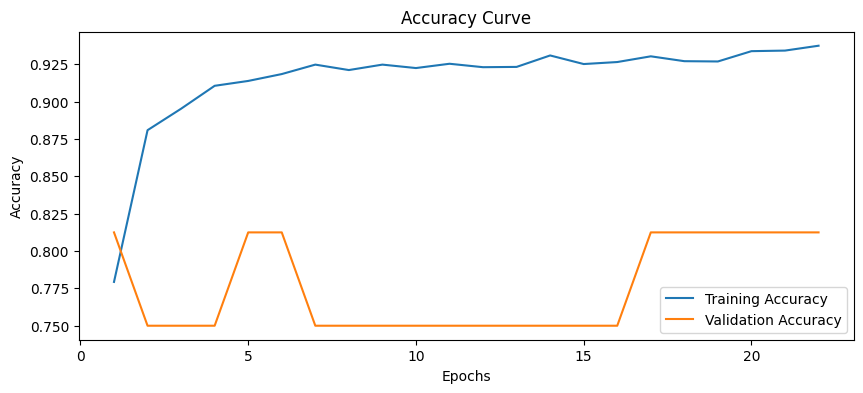

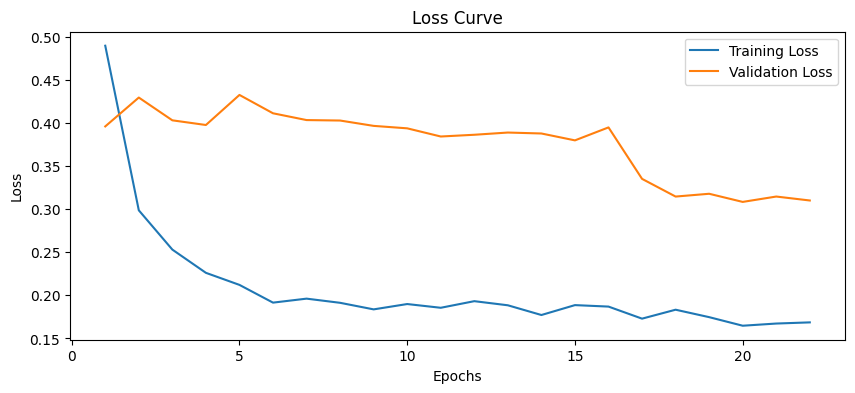

In [21]:
def plot_training_curves(history, history_fine=None):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    if history_fine:
        acc += history_fine.history['accuracy']
        val_acc += history_fine.history['val_accuracy']
        loss += history_fine.history['loss']
        val_loss += history_fine.history['val_loss']

    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(10,4))
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy')
    plt.legend(); plt.title('Accuracy Curve'); plt.show()

    plt.figure(figsize=(10,4))
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.xlabel('Epochs'); plt.ylabel('Loss')
    plt.legend(); plt.title('Loss Curve'); plt.show()

plot_training_curves(history, history_fine)


20/20 ━━━━━━━━━━━━━━━━━━━━ 65s 3s/step
              precision    recall  f1-score   support

      NORMAL       0.85      0.88      0.87       234
   PNEUMONIA       0.93      0.91      0.92       390

    accuracy                           0.90       624
   macro avg       0.89      0.89      0.89       624
weighted avg       0.90      0.90      0.90       624



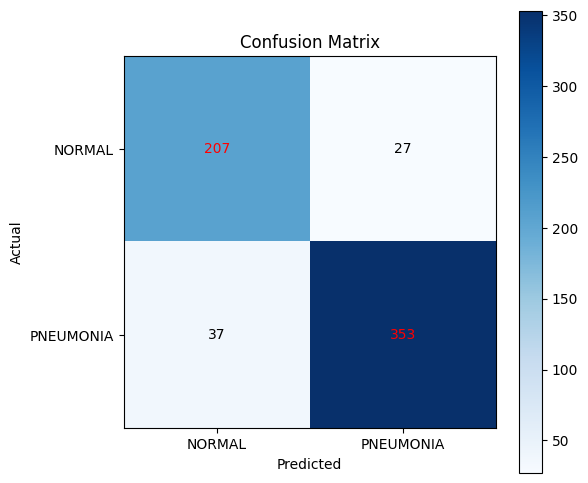

Accuracy  : 0.8974
Precision : 0.8987
Recall    : 0.8974
F1 Score  : 0.8978


In [ ]:
y_true = test_generator.classes
y_pred_probs = model.predict(test_generator)
y_pred = np.argmax(y_pred_probs, axis=1)
class_names = list(test_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,6))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(len(class_names)), class_names)
plt.yticks(range(len(class_names)), class_names)
plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i,j], ha='center', va='center', color="red" if cm[i,j]>cm.max()/2 else "black")

plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall    = recall_score(y_true, y_pred, average='weighted')
f1        = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


In [24]:
model.save("densenet_final_model.h5")
print("DenseNet model saved successfully at /kaggle/working/densenet_final_model.h5")


DenseNet model saved successfully at /kaggle/working/densenet_final_model.h5
